表示は小数点以下3桁に統一し、回数・通り数は整数、厳密な確率は分数で示します。計算値は丸めずに保持します。
丸めて1.000と表示されても厳密な確率1を意味しません。心理的な違和感の発生率はこのノートブックでは推定していません。


# シゴロ賽の有利さと逐次ベイズ更新：モデル整理版

2026年11月3日改訂。最終目標は、通常賽同士と456賽対通常賽の**配当を含む純損益期待値**を比較することです。今回は優先事項の修正と、役確率の厳密な計数まで行います。

## 分析上の約束

- 推定量は、定義した2仮説の間での「456賽を使用する戦略の事後確率」です。人間が疑い始める心理の実測値ではありません。
- 導入の1観測は**単一賽の出目**です。Highは4・5・6のいずれか、Lowは1・2・3のいずれかを指します。「456の役」と区別します。
- その後、3個の賽を同時に振る1投、振り直しを含む1手番へ拡張します。賽3個は同じ種類の一式として選びます。
- 事前確率10.000％、456賽使用率90.000％、独立で一様な出目、持ち替えのタイミングは、本稿の説明用仮定です。原作の実測値・確定設定として扱いません。
- 通常賽の平均3.500、456賽の平均5.000は出目の平均です。勝率・配当・損益の期待値とは別の量です。
- 基準設定は事前確率10.000％、観測数20、乱数seed=20261103です。事前確率の影響を見る節では比較用の値を使います。
### 表示上の約束
全4グラフのx軸は整数の目盛りと整数表記に統一し、0は観測前の事前確率を表します。確率を表すy軸は従来どおり小数で表示します。


In [1]:
import math
import random
from itertools import product
from collections import Counter
from fractions import Fraction
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

from decimal import Decimal, ROUND_HALF_UP, localcontext
def _fmt_number(value, percent=False):
    with localcontext() as ctx:
        ctx.prec = 60
        x = Decimal(value.numerator)/Decimal(value.denominator) if isinstance(value, Fraction) else Decimal(str(value))
        if percent:
            x *= 100
        result = format(x.quantize(Decimal("0.001"), rounding=ROUND_HALF_UP), ".3f")
    return result + ("%" if percent else "")

PRIOR = Fraction(1, 10)  # 観測前の事前確率。旧版のコメント10％・実値50％の不一致を修正
CHEAT_RATE = Fraction(9, 10)  # H1の既知の使用率。データから推定している値ではない
N_OBSERVATIONS = 20
SEED = 20261103

def bayes_update(prior, likelihood_h1, likelihood_h0):
    prior = Fraction(prior) if isinstance(prior, Fraction) else Fraction(str(prior))
    likelihood_h1 = Fraction(likelihood_h1) if isinstance(likelihood_h1, Fraction) else Fraction(str(likelihood_h1))
    likelihood_h0 = Fraction(likelihood_h0) if isinstance(likelihood_h0, Fraction) else Fraction(str(likelihood_h0))
    if not (0 <= prior <= 1):
        raise ValueError("prior must lie in [0, 1]")
    evidence = prior * likelihood_h1 + (1 - prior) * likelihood_h0
    if evidence <= 0:
        raise ValueError("Observation has zero probability under both weighted hypotheses")
    return prior * likelihood_h1 / evidence

def update_single_die(prior, high, cheat_rate=1):
    # H0: 通常賽、H1: 各観測で確率cheat_rateにより456賽を選ぶ
    p_high_h1 = (1 + cheat_rate) / 2
    likelihood_h1 = p_high_h1 if high else 1 - p_high_h1
    return bayes_update(prior, likelihood_h1, Fraction(1, 2))

def single_die_history(observations, prior=PRIOR, cheat_rate=1):
    history = [prior]
    for high in observations:
        history.append(update_single_die(history[-1], high, cheat_rate))
    return history

def format_count_axis(ax, count):
    """回数の軸は0からcountまで、整数の位置・整数の表記に統一する。"""
    ax.set_xlim(0, count)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.3f}"))

print(f'prior={_fmt_number(PRIOR, percent=True)}, cheat_rate={_fmt_number(CHEAT_RATE, percent=True)}, observations={N_OBSERVATIONS}, seed={SEED}')

prior=10.000%, cheat_rate=90.000%, observations=20, seed=20261103


## 1. 導入：純粋な456賽と通常賽

$H_0$は常に通常賽、$H_1$は常に456賽を使う仮説です。$p_t=P(H_1\mid D_{1:t})$とすると、

$$p_t=\frac{P(D_t\mid H_1)p_{t-1}}
{P(D_t\mid H_1)p_{t-1}+P(D_t\mid H_0)(1-p_{t-1})}.$$

High1回の尤度比は2です。Highが$n$回続いた場合、

$$p_n=\frac{p_0 2^n}{1-p_0+p_0 2^n}.$$

Lowが出ると、この厳密な$H_1$の事後確率は0になります。これは「不正一般」が否定されたことを意味しません。

High  1回: P(H1|data)=0.182
High  7回: P(H1|data)=0.934
High 10回: P(H1|data)=0.991
High 20回: P(H1|data)=1.000


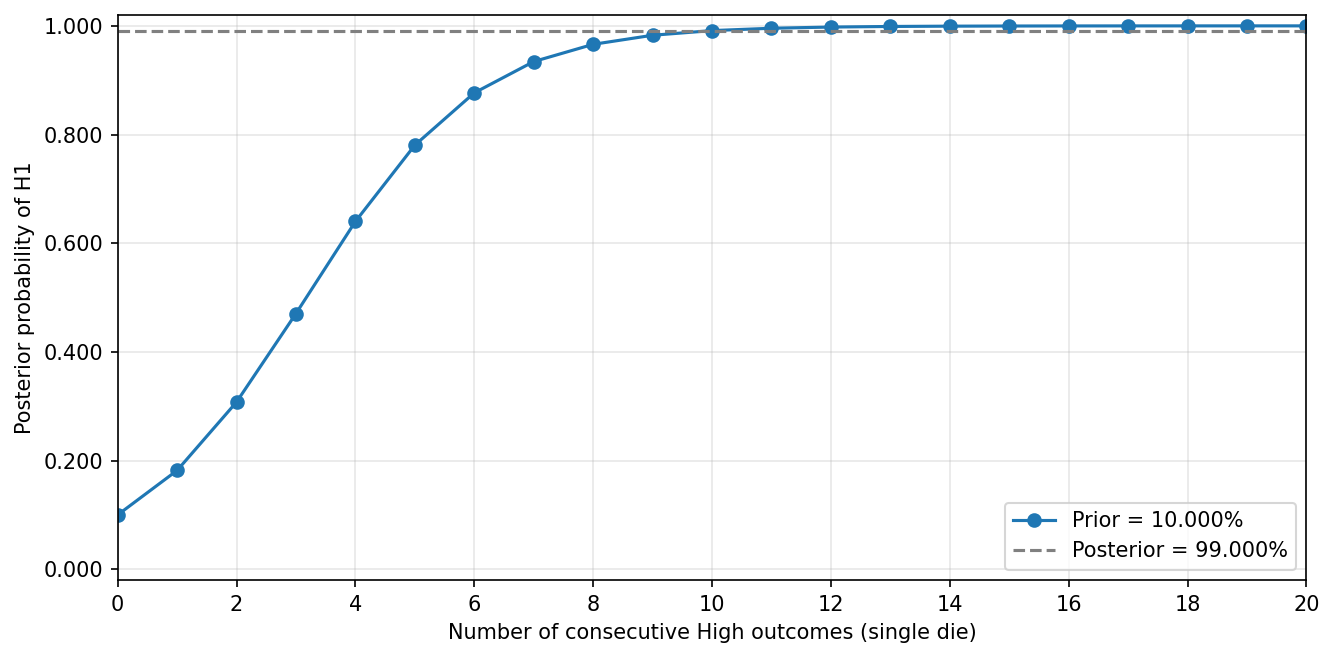

In [2]:
history = single_die_history([True] * N_OBSERVATIONS)
for n in [1, 7, 10, 20]:
    print(f'High {n:2d}回: P(H1|data)={_fmt_number(history[n])}')
plt.figure(figsize=(9, 4.5))
plt.plot(range(N_OBSERVATIONS + 1), history, marker="o", label="Prior = 10.000%")
plt.axhline(0.99, color="gray", linestyle="--", label="Posterior = 99.000%")
plt.xlabel("Number of consecutive High outcomes (single die)")
plt.ylabel("Posterior probability of H1")
plt.ylim(-0.02, 1.02)
plt.grid(alpha=0.3)
plt.legend()
format_count_axis(plt.gca(), N_OBSERVATIONS)
plt.tight_layout()
plt.show()

## 2. 事前確率とp値の区別

開始点と観測数$n$を固定した片側二項検定では、全回Highという観測のp値は$2^{-n}$です。7回なら0.008ですが、これは$P(H_0\mid D)$ではありません。

7回のHigh後に99.000％を超えるのは、純粋モデルで事前確率を50.000％にした場合です。事前確率10.000％なら10回が必要です。長い系列から7連続Highを探す場合や繰り返し検定をする場合、そのp値を全体の誤検出率にはできません。

比較する事前確率は説明用の設定です。「中立」「疑い深い」といった心理的属性は付与しません。

prior | posterior after 7 High | first n >=99.000%: pure / mixture
1.000% | 56.388% | 14 / 15
10.000% | 93.431% | 10 / 11
20.000% | 96.970% |  9 / 10
50.000% | 99.225% |  7 /  8


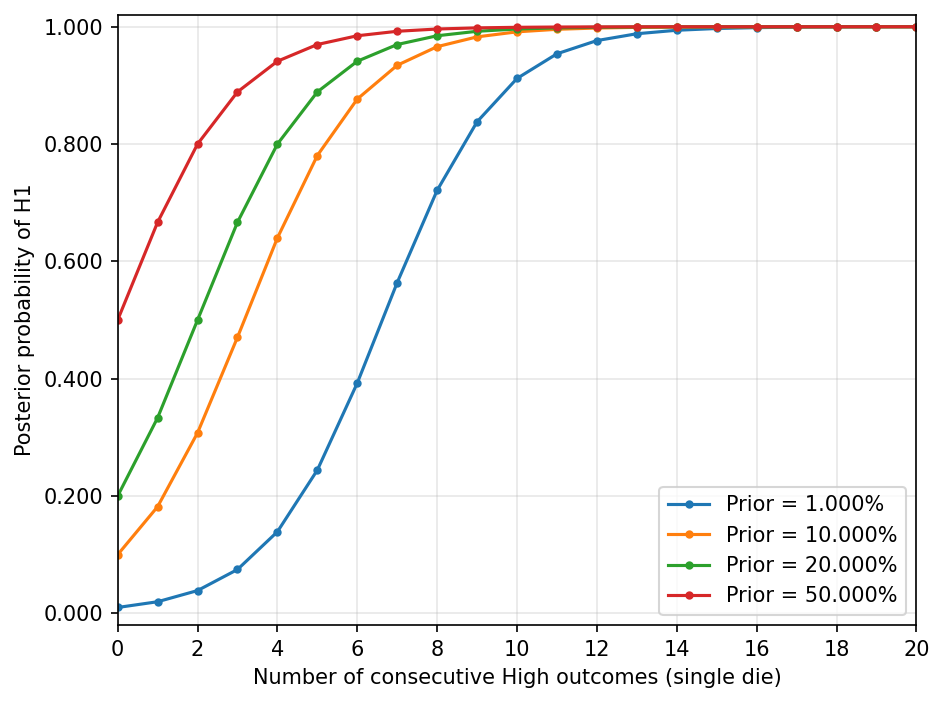

Fixed-n one-sided p-value for 7 High: 0.008


In [3]:
priors = [0.01, 0.10, 0.20, 0.50]
print("prior | posterior after 7 High | first n >=99.000%: pure / mixture")
for prior in priors:
    pure = single_die_history([True] * 40, prior, 1.0)
    mixed = single_die_history([True] * 40, prior, CHEAT_RATE)
    n_pure = next(n for n, p in enumerate(pure) if p >= 0.99)
    n_mixed = next(n for n, p in enumerate(mixed) if p >= 0.99)
    print(f'{_fmt_number(prior, percent=True)} | {_fmt_number(pure[7], percent=True)} | {n_pure:2d} / {n_mixed:2d}')
    plt.plot(range(21), pure[:21], marker=".", label=f'Prior = {_fmt_number(prior, percent=True)}')
plt.xlabel("Number of consecutive High outcomes (single die)")
plt.ylabel("Posterior probability of H1")
plt.ylim(-0.02, 1.02)
plt.grid(alpha=0.3)
plt.legend()
format_count_axis(plt.gca(), N_OBSERVATIONS)
plt.tight_layout()
plt.show()
print(f'Fixed-n one-sided p-value for 7 High: {_fmt_number(0.5 ** 7)}')

## 3. 単一賽の混合モデル

$H_1$を「観測ごとに確率$\eta=0.900$で456賽、確率0.100で通常賽を選ぶ」と変更します。

$$P(H\mid H_1)=0.950,\qquad P(L\mid H_1)=0.05.$$

Highでオッズは1.900倍、Lowで0.100倍です。以下の生成側の真の仮説は$H_1$です。この1系列だけでは、誤検出率や平均検知回数は評価できません。観測系列とseedを出力します。

Observations: HHLHHHHHHHHHHHHHHHHH
Final posterior: 1.000


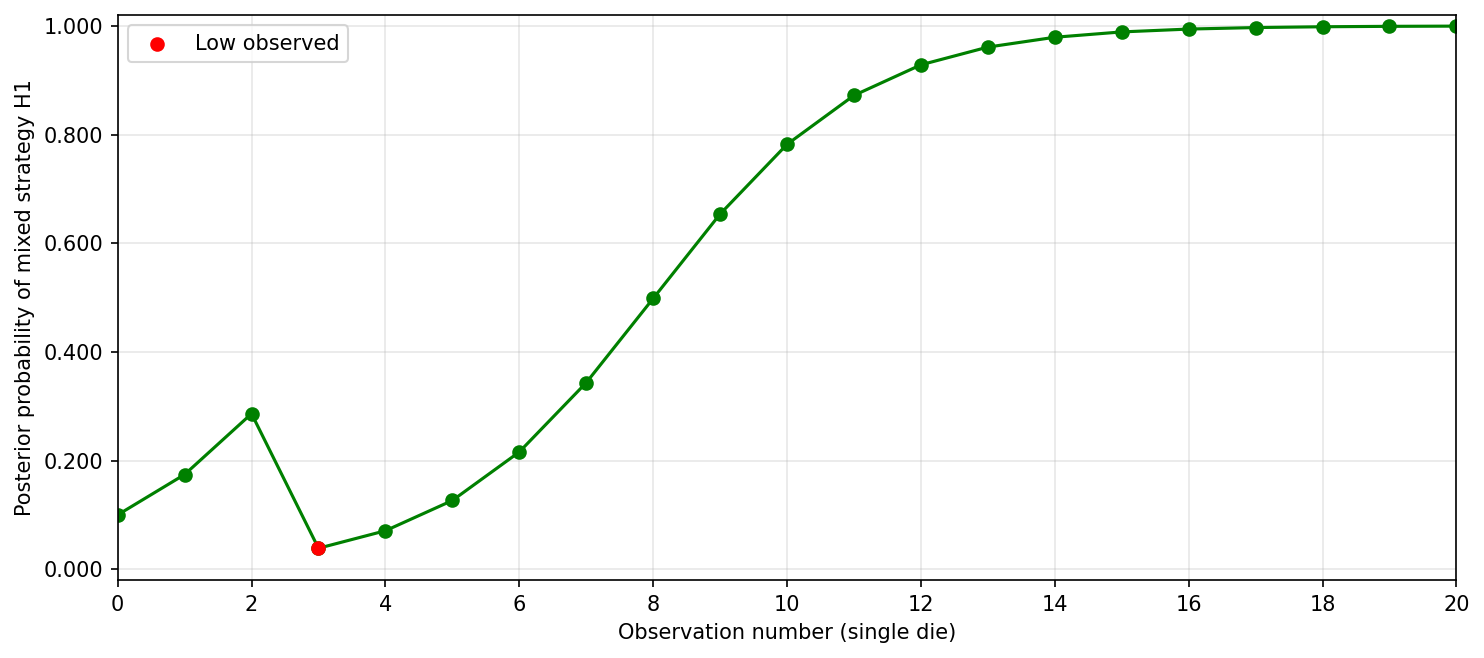

In [4]:
rng = random.Random(SEED)
observations = []
for _ in range(N_OBSERVATIONS):
    use_456 = rng.random() < CHEAT_RATE
    face = rng.choice((4, 5, 6) if use_456 else (1, 2, 3, 4, 5, 6))
    observations.append(face >= 4)
history = single_die_history(observations, cheat_rate=CHEAT_RATE)
print("Observations:", "".join("H" if high else "L" for high in observations))
print(f'Final posterior: {_fmt_number(history[-1])}')
plt.figure(figsize=(10, 4.5))
plt.plot(range(N_OBSERVATIONS + 1), history, marker="o", color="green")
low_indices = [i + 1 for i, high in enumerate(observations) if not high]
plt.scatter(low_indices, [history[i] for i in low_indices], color="red", zorder=3, label="Low observed")
plt.xlabel("Observation number (single die)")
plt.ylabel("Posterior probability of mixed strategy H1")
plt.ylim(-0.02, 1.02)
plt.grid(alpha=0.3)
plt.legend()
format_count_axis(plt.gca(), N_OBSERVATIONS)
plt.tight_layout()
plt.show()

## 4. 3個一式・1手番のモデル

期待値計算へ接続する基本単位を以下のように定義します。

| 単位 | 定義 |
| --- | --- |
| 1個の出目 | 導入のHigh/Lowモデルの観測単位 |
| 1投 | 同じ種類の賽3個を同時に振ること |
| 1手番 | 役が成立するまで最大3投すること |
| 1対戦 | 親と子1人がそれぞれの最終役を比べて精算すること |

拡張モデルでは、$H_1$の相手は**手番の開始時に確率90.000％で456賽一式を選び、その手番の振り直し中は同じ一式を維持する**と仮定します。手番間の選択は独立です。観測データは各手番の全投擲履歴とし、最終役だけを観測するモデルとは区別します。

1投の具体的な出目$\mathbf{x}=(x_1,x_2,x_3)$について、通常賽は$1/216$、456賽は全個体Highなら$1/27$、それ以外は0です。

$$P(\mathbf{x}\mid H_1)=\eta\,P_{456}(\mathbf{x})+(1-\eta)P_F(\mathbf{x}).$$

最初の1投が全個体Highなら尤度比は$1+7\eta=7.300$です。Lowを含めば$1-\eta=0.100$です。周辺のHigh確率0.950を3回独立に掛けた$1.900^3$とは異なります。

手番$T$が複数投を含む場合は、通常賽と456賽それぞれで手番全体の尤度を計算してから混合します。

$$P(T\mid H_1)=\eta\prod_j P_{456}(\mathbf{x}_j)+(1-\eta)\prod_j P_F(\mathbf{x}_j).$$

途中で種類を選び直さないため、混合尤度を投ごとに掛ける式にはしません。停止規則は両仮説で共通で、観測された有効な手番に対して上式を使います。

手番 1: [(4, 4, 4)], 最終役=ゾロ目(2〜6), posterior=0.448
手番 2: [(6, 4, 4)], 最終役=6の目, posterior=0.856
手番 3: [(6, 6, 6)], 最終役=ゾロ目(2〜6), posterior=0.977
手番 4: [(4, 4, 5)], 最終役=5の目, posterior=0.997
手番 5: [(5, 6, 6)], 最終役=5の目, posterior=1.000
手番 6: [(5, 5, 6)], 最終役=6の目, posterior=1.000
手番 7: [(5, 4, 4)], 最終役=5の目, posterior=1.000
手番 8: [(4, 4, 5)], 最終役=5の目, posterior=1.000
手番 9: [(5, 4, 4)], 最終役=5の目, posterior=1.000
手番10: [(4, 4, 5)], 最終役=5の目, posterior=1.000
手番11: [(4, 6, 5)], 最終役=シゴロ, posterior=1.000
手番12: [(1, 5, 1)], 最終役=5の目, posterior=1.000
手番13: [(5, 4, 5)], 最終役=4の目, posterior=1.000
手番14: [(6, 6, 5)], 最終役=5の目, posterior=1.000
手番15: [(4, 4, 6)], 最終役=6の目, posterior=1.000
手番16: [(5, 4, 6)], 最終役=シゴロ, posterior=1.000
手番17: [(6, 5, 6)], 最終役=5の目, posterior=1.000
手番18: [(6, 5, 4)], 最終役=シゴロ, posterior=1.000
手番19: [(4, 4, 6)], 最終役=6の目, posterior=1.000
手番20: [(5, 5, 6)], 最終役=6の目, posterior=1.000


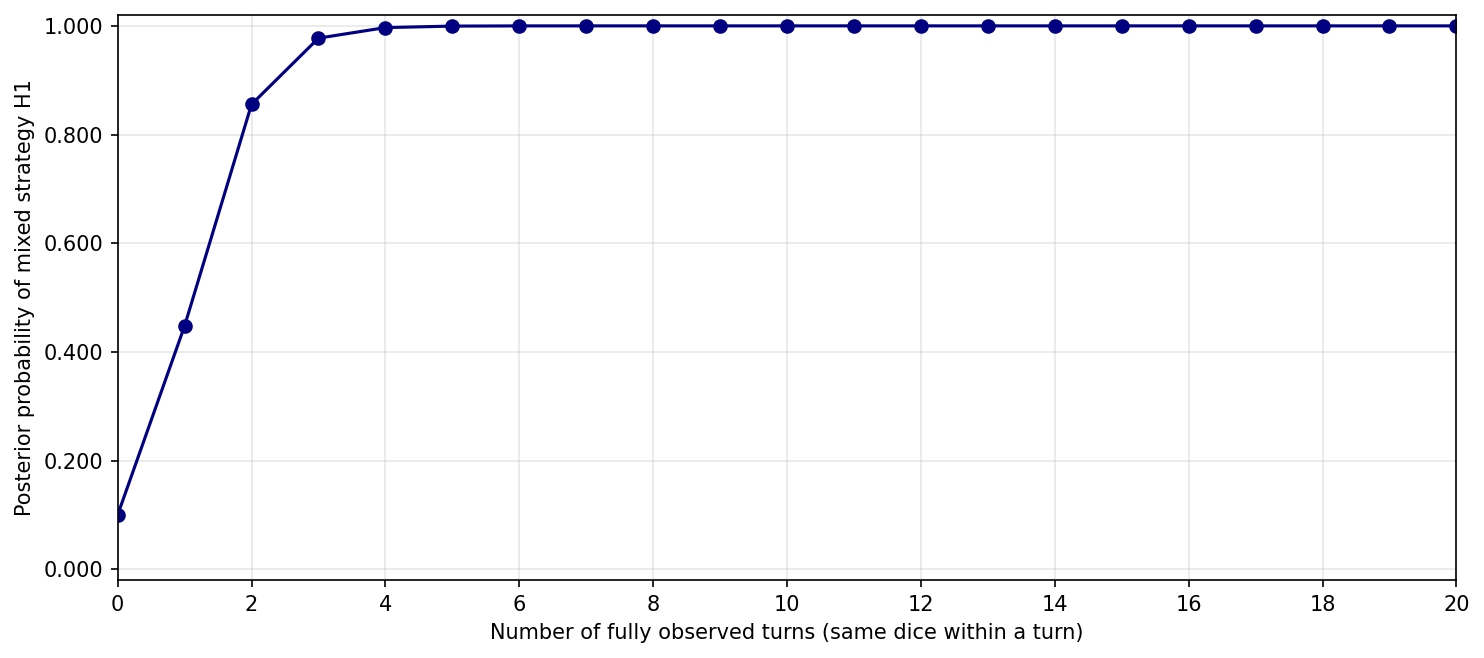

In [5]:
FAIR_FACES = (1, 2, 3, 4, 5, 6)
RIGGED_FACES = (4, 5, 6)
ROLE_ORDER = ["pin", "triple", "456", "point_6", "point_5", "point_4",
              "point_3", "point_2", "point_1", "none", "123"]
ROLE_NAMES = {"pin": "ピンゾロ", "triple": "ゾロ目(2〜6)", "456": "シゴロ",
              "none": "目なし", "123": "ヒフミ",
              **{f'point_{k}': f'{k}の目' for k in range(1, 7)}}

def classify_roll(roll):
    if len(roll) != 3 or any(x not in FAIR_FACES for x in roll):
        raise ValueError("roll must contain three integer faces in 1..6")
    a, b, c = sorted(roll)
    if a == c:
        return "pin" if a == 1 else "triple"
    if (a, b, c) == (1, 2, 3):
        return "123"
    if (a, b, c) == (4, 5, 6):
        return "456"
    if a == b:
        return f'point_{c}'
    if b == c:
        return f'point_{a}'
    return "none"

def simulate_turn(rng, cheat_rate):
    # 一式の選択は手番の最初の1回だけ
    use_456 = rng.random() < cheat_rate
    faces = RIGGED_FACES if use_456 else FAIR_FACES
    rolls = []
    for _ in range(3):
        roll = tuple(rng.choice(faces) for _ in range(3))
        rolls.append(roll)
        if classify_roll(roll) != "none":
            break
    return rolls

def turn_likelihood(rolls, faces):
    if not 1 <= len(rolls) <= 3:
        raise ValueError("A turn must contain one to three rolls")
    roles = [classify_roll(roll) for roll in rolls]
    if any(role != "none" for role in roles[:-1]):
        raise ValueError("A completed role must end the turn")
    if len(rolls) < 3 and roles[-1] == "none":
        raise ValueError("The turn stopped before its stopping rule")
    if any(x not in faces for roll in rolls for x in roll):
        return Fraction(0)
    return Fraction(1, len(faces)**3) ** len(rolls)

def update_turn(prior, rolls, cheat_rate=CHEAT_RATE):
    fair = turn_likelihood(rolls, FAIR_FACES)
    pure = turn_likelihood(rolls, RIGGED_FACES)
    mixed = cheat_rate * pure + (1 - cheat_rate) * fair
    return bayes_update(prior, mixed, fair)

rng = random.Random(SEED)
turns = [simulate_turn(rng, CHEAT_RATE) for _ in range(N_OBSERVATIONS)]
turn_history = [PRIOR]
for i, rolls in enumerate(turns, 1):
    turn_history.append(update_turn(turn_history[-1], rolls))
    role = ROLE_NAMES[classify_roll(rolls[-1])]
    print(f'手番{i:2d}: {rolls}, 最終役={role}, posterior={_fmt_number(turn_history[-1])}')

plt.figure(figsize=(10, 4.5))
plt.plot(range(N_OBSERVATIONS + 1), turn_history, marker="o", color="navy")
plt.xlabel("Number of fully observed turns (same dice within a turn)")
plt.ylabel("Posterior probability of mixed strategy H1")
plt.ylim(-0.02, 1.02)
plt.grid(alpha=0.3)
format_count_axis(plt.gca(), N_OBSERVATIONS)
plt.tight_layout()
plt.show()

## 5. 期待値計算の土台：役分布を全列挙する

独立で一様な通常賽3個の順序付き出目は$6^3=216$通り、456賽3個では$3^3=27$通りです。丼からこぼれる事象は今回は除外します。

通常の目は「2個が同じで、残りの1個が$k$」です。通常賽では各目15通り、456賽では4・5・6の各目が6通りです。

1投の目なし確率を$q$とすると、目なしだけを振り直す最大3投の手番について、成立役$r$の確率は、

$$P_{\mathrm{turn}}(r)=P_{\mathrm{roll}}(r)(1+q+q^2),\qquad
P_{\mathrm{turn}}(\mathrm{none})=q^3.$$

これは「1投で役が出るまで際限なく振る」条件付き分布とは異なります。456賽では$q=0$なので、必ず1投で役が成立します。

手番開始時に賽を選んで維持する混合戦略なら、最終役分布は
$\eta P_{\mathrm{turn},456}+(1-\eta)P_{\mathrm{turn},F}$です。投ごとに選び直す場合とは区別します。

In [6]:
def exact_roll_distribution(faces):
    outcomes = list(product(faces, repeat=3))
    counts = Counter(classify_roll(roll) for roll in outcomes)
    return {role: Fraction(counts[role], len(outcomes)) for role in ROLE_ORDER}

def exact_turn_distribution(roll_distribution):
    q = roll_distribution["none"]
    return {role: q**3 if role == "none" else p * (1 + q + q*q)
            for role, p in roll_distribution.items()}

fair_roll = exact_roll_distribution(FAIR_FACES)
rigged_roll = exact_roll_distribution(RIGGED_FACES)
fair_turn = exact_turn_distribution(fair_roll)
rigged_turn = exact_turn_distribution(rigged_roll)
mixed_turn = {role: Fraction(9, 10)*rigged_turn[role] + Fraction(1, 10)*fair_turn[role]
              for role in ROLE_ORDER}

print("役 | 通常賽1投 | 456賽1投 | 通常賽1手番 | 456賽1手番")
for role in ROLE_ORDER:
    print(f'{ROLE_NAMES[role]} | {fair_roll[role]} | {rigged_roll[role]} | {fair_turn[role]} | {rigged_turn[role]}')

assert fair_roll["none"] == Fraction(1, 2)
assert rigged_roll["none"] == 0
assert fair_turn["none"] == Fraction(1, 8)
assert fair_roll["pin"] == Fraction(1, 216)
assert rigged_roll["triple"] == Fraction(1, 9)
assert rigged_roll["456"] == Fraction(2, 9)
for distribution in (fair_roll, rigged_roll, fair_turn, rigged_turn, mixed_turn):
    assert sum(distribution.values()) == 1

# 逐次更新と閉形式の独立な一致確認
for n in range(1, 9):
    for outcomes in product((False, True), repeat=n):
        sequential = single_die_history(outcomes, PRIOR, CHEAT_RATE)[-1]
        h, l = sum(outcomes), n - sum(outcomes)
        odds = PRIOR/(1-PRIOR) * (1+CHEAT_RATE)**h * (1-CHEAT_RATE)**l
        assert math.isclose(sequential, odds/(1+odds), rel_tol=1e-10, abs_tol=1e-12)
assert math.isclose(turn_likelihood([(4, 5, 6)], RIGGED_FACES) /
                    turn_likelihood([(4, 5, 6)], FAIR_FACES), 8.0)
assert math.isclose(update_turn(PRIOR, [(4, 5, 6)]), 7.3/(9+7.3))
assert math.isclose(update_turn(PRIOR, [(1, 4, 4)]), 0.1/(9+0.1))
for rolls in turns:
    normal = turn_likelihood(rolls, FAIR_FACES)
    pure = turn_likelihood(rolls, RIGGED_FACES)
    bf = (CHEAT_RATE*pure + (1-CHEAT_RATE)*normal)/normal
    expected = 7.3 if all(x >= 4 for x in rolls[0]) else 0.1
    assert math.isclose(bf, expected)
print("Verified: exact normalization, role counts, 510 sequential-update cases, grouped likelihoods.")

役 | 通常賽1投 | 456賽1投 | 通常賽1手番 | 456賽1手番
ピンゾロ | 1/216 | 0 | 7/864 | 0
ゾロ目(2〜6) | 5/216 | 1/9 | 35/864 | 1/9
シゴロ | 1/36 | 2/9 | 7/144 | 2/9
6の目 | 5/72 | 2/9 | 35/288 | 2/9
5の目 | 5/72 | 2/9 | 35/288 | 2/9
4の目 | 5/72 | 2/9 | 35/288 | 2/9
3の目 | 5/72 | 0 | 35/288 | 0
2の目 | 5/72 | 0 | 35/288 | 0
1の目 | 5/72 | 0 | 35/288 | 0
目なし | 1/2 | 0 | 1/8 | 0
ヒフミ | 1/36 | 0 | 7/144 | 0
Verified: exact normalization, role counts, 510 sequential-update cases, grouped likelihoods.


## 6. 次に計算する期待値の定義

基準は「賭け金1単位、通常賽の子1人と対戦する親の、1対戦当たりの純損益」です。勝ちなら正、負けなら負、同点返却なら0とします。

$$E[G]=\sum_{r,s}P_{\mathrm{parent}}(r)P_{\mathrm{child}}(s)g(r,s).$$

ここで$g(r,s)$は、役の強弱と配当から定まる損益表です。役の番号を平均する計算ではありません。

次の比較を行えるよう、役分布は既に計算済みです。

1. 通常賽の親 対 通常賽の子。
2. 456賽の親 対 通常賽の子。
3. 手番ごとに90.000％で456賽を選ぶ親 対 通常賽の子。

損益の数値を確定する前に、同格のゾロ目を引き分けとするか、ヒフミと特殊役の倍率を掛け合わせるかなど、配当表を明文化します。丼からの落下、参加費、親番の継続、複数の子、破産・賭け金上限は別の拡張です。

### 参照した公開ルール

[777TOWN.net「帝愛カジノ：対局ルールと役一覧」](https://www.777town.net/casino/chinchirorin/rule.jsp)（2026年11月3日確認）は、3個の賽・最大3投・親の総取りなし等を記載しています。ただし原作そのものではなく、同サービスのルール資料です。本ノートブックの仮定と原作の一致を保証する資料としては扱いません。配当画像の内容は今回の計算に使用していません。